# 14 — Model Interpretation and Error Analysis

[Previous](./13_Calibration_and_Thresholds.ipynb) | [Repository guide](../README.md) | [Next](./15_Final_Frozen_Solution.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** understand what the frozen pipeline uses, where it succeeds, and where it still makes mistakes.

All reported scores use training-only **out-of-fold (OOF)** predictions. Test labels remain sealed.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


## 1. Pipeline recap

| Phase | What we learned | Decision carried forward |
|---|---|---|
| EDA | 20,000 training rows, 6,000 test rows, no duplicates, mild 55/45 imbalance, and small amounts of missing data | Keep IDs out of the model and investigate train/test differences |
| Validation | One split can be lucky | Use stratified five-fold OOF F1 |
| Missing values | Several imputers scored similarly | Numerical median; categorical most-frequent value |
| Scaling | Scaling helps the neural network and comparable pipelines | StandardScaler after numerical imputation |
| Categorical encoding | More complex encoders gave no clear stable gain | One-hot encoding with unknown categories ignored |
| Feature engineering | Relative skill, pressure, match state, interactions, and nonlinear features added useful signal | Use the full 49-column engineered set |
| Feature selection | A smaller L1 set was competitive for a linear model | Keep the named features for the nonlinear ensemble and interpretation |
| Dimensionality reduction | Compact components lost signal and hide feature meaning | No PCA/LDA reduction in the final pipeline |
| Outliers | A large CV gain depended on an extreme-value pattern that shifted between train and test | Keep original values; do not remove rows |
| Class imbalance | Resampling changed F1 by almost nothing | Keep the original 55/45 class distribution |
| Model choice | Boosted trees and an MLP were strongest and learn differently | Tuned CatBoost + LightGBM + MLP |
| Ensemble | Equal soft voting improved over the best individual model | Average the three probabilities |
| Calibration | Isotonic calibration improved probability reliability | Fit isotonic calibration from training-only OOF probabilities |
| Threshold | Learned thresholds stayed close to 0.50 | Freeze the class threshold at 0.50 |

This recap describes the **chosen pipeline**. Earlier alternatives remain useful learning experiments, even when they were not selected.


## 2. Interpretation and error-analysis methods

| Method | Beginner meaning | Benefit | Limitation | Used here? |
|---|---|---|---|---|
| Built-in tree importance | How much a tree model used each feature in its splits | Fast | Can favor features with many possible split points | Yes |
| Permutation importance | Shuffle one feature and measure how much validation performance falls | Model-agnostic and held-out | Correlated features can share or hide importance | **Main method** |
| SHAP | Divide one prediction among its feature contributions | Global and local explanations | More computation; values depend on the explained model/background | Explained alternative |
| Partial dependence (PDP) | Average prediction while one feature is varied | Shows direction and nonlinearity | Can create unrealistic combinations for correlated features | Yes, for LightGBM |
| ICE | One PDP-like line per row | Reveals different row-level behavior | Can become visually crowded | Explained alternative |
| ALE | Average local changes where data actually exists | Better with correlated features | Less familiar and harder to explain | Explained alternative |
| Surrogate tree | Train a small tree to imitate the complex model | Easy summary | Explains the imitation, not the original model | Explained alternative |
| Local sensitivity | Replace one value and observe the probability change | Concrete row example | It is sensitivity, not a causal claim | Yes |

Error analysis adds a confusion matrix, high-confidence errors, probability buckets, and subgroup checks.


In [1]:
from time import perf_counter
import hashlib
import json
import warnings

# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore", message="X does not have valid feature names")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

fingerprint_values = pd.util.hash_pandas_object(
    train.sort_index(axis=1), index=True
).values.tobytes()
dataset_fingerprint = hashlib.sha256(fingerprint_values).hexdigest()[:12]

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")
print(f"Dataset fingerprint: {dataset_fingerprint}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
Dataset fingerprint: 3bc8d73b8f62


## 3. Rebuild leakage-safe OOF predictions

For every outer fold:

1. fit the three models without that fold;
2. predict the untouched fold and average their probabilities;
3. build inner OOF probabilities using only the outer-training rows;
4. fit isotonic calibration on those inner predictions;
5. apply it to the untouched outer fold.

The same held-out folds are also used for permutation importance. **Leakage-safe** means an evaluated label did not help train its model or calibrator.


In [4]:


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result


X = add_engineered_features(train.drop(columns=[TARGET] + ID_COLUMNS))
y = train[TARGET].astype(int)
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y))

print(f"Model inputs: {X.shape[1]} columns before one-hot encoding")
print(f"Numerical: {len(numerical_columns)} | Categorical: {len(categorical_columns)} | Folds: {len(folds)}")

Model inputs: 49 columns before one-hot encoding
Numerical: 44 | Categorical: 5 | Folds: 5


In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ], sparse_threshold=0)

In [6]:
base_models = {
    "CatBoost": CatBoostClassifier(
        iterations=300,
        learning_rate=0.025,
        depth=8,
        l2_leaf_reg=5,
        random_strength=0.5,
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=600,
        learning_rate=0.025,
        num_leaves=15,
        max_depth=8,
        min_child_samples=10,
        subsample=1.0,
        subsample_freq=1,
        colsample_bytree=0.75,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1,
    ),
    "Multilayer perceptron": MLPClassifier(
        hidden_layer_sizes=(96, 48),
        activation="tanh",
        learning_rate_init=0.003,
        batch_size=256,
        alpha=0.01,
        max_iter=250,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    ),
}

base_summary = pd.DataFrame([
    ["CatBoost", "ordered boosted trees", "strong nonlinear interactions"],
    ["LightGBM", "leaf-wise boosted trees", "fast alternative tree rules"],
    ["Multilayer perceptron", "layers of nonlinear weights", "different learning mechanism"],
], columns=["base model", "how it learns", "why it may add diversity"])
display(base_summary.style.hide(axis="index"))


base model,how it learns,why it may add diversity
CatBoost,ordered boosted trees,strong nonlinear interactions
LightGBM,leaf-wise boosted trees,fast alternative tree rules
Multilayer perceptron,layers of nonlinear weights,different learning mechanism


In [7]:
def encoded_to_source_feature(encoded_name):
    name = encoded_name.split("__", 1)[-1]
    for column in sorted(categorical_columns, key=len, reverse=True):
        if name == column or name.startswith(f"{column}_"):
            return column
    return name


def training_references(frame):
    references = {}
    for column in frame.columns:
        if column in numerical_columns:
            references[column] = frame[column].median()
        else:
            modes = frame[column].mode(dropna=True)
            references[column] = modes.iloc[0] if len(modes) else np.nan
    return references


def predict_ensemble(fitted_models, frame):
    probabilities = [
        pipeline.predict_proba(frame)[:, 1]
        for pipeline in fitted_models.values()
    ]
    return np.column_stack(probabilities).mean(axis=1)


In [8]:
oof_raw_probability = np.zeros(len(y), dtype=float)
oof_calibrated_probability = np.zeros(len(y), dtype=float)
outer_fold_for_row = np.zeros(len(y), dtype=int)

permutation_rows = []
builtin_rows = []
fold_bundles = {}

experiment_start = perf_counter()
for outer_fold, (outer_train_index, outer_valid_index) in enumerate(folds, start=1):
    X_outer_train = X.iloc[outer_train_index]
    y_outer_train = y.iloc[outer_train_index]
    X_outer_valid = X.iloc[outer_valid_index]
    y_outer_valid = y.iloc[outer_valid_index]

    fitted_models = {}
    outer_base_probabilities = []
    for model_name, estimator in base_models.items():
        pipeline = Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", clone(estimator)),
        ])
        pipeline.fit(X_outer_train, y_outer_train)
        fitted_models[model_name] = pipeline
        outer_base_probabilities.append(
            pipeline.predict_proba(X_outer_valid)[:, 1]
        )

        model = pipeline.named_steps["model"]
        if hasattr(model, "feature_importances_"):
            encoded_names = pipeline.named_steps[
                "preprocessor"
            ].get_feature_names_out()
            importance = np.asarray(model.feature_importances_, dtype=float)
            importance = importance / importance.sum()
            fold_importance = pd.DataFrame({
                "feature": [
                    encoded_to_source_feature(name) for name in encoded_names
                ],
                "importance": importance,
            }).groupby("feature", as_index=False)["importance"].sum()
            for row in fold_importance.itertuples(index=False):
                builtin_rows.append({
                    "outer_fold": outer_fold,
                    "model": model_name,
                    "feature": row.feature,
                    "importance": row.importance,
                })

    raw_valid_probability = np.column_stack(
        outer_base_probabilities
    ).mean(axis=1)
    oof_raw_probability[outer_valid_index] = raw_valid_probability

    inner_folds = list(
        StratifiedKFold(
            n_splits=4,
            shuffle=True,
            random_state=RANDOM_STATE + outer_fold,
        ).split(X_outer_train, y_outer_train)
    )
    inner_base_probability = np.zeros(
        (len(outer_train_index), len(base_models)), dtype=float
    )
    for model_index, (model_name, estimator) in enumerate(base_models.items()):
        inner_pipeline = Pipeline([
            ("preprocessor", make_preprocessor()),
            ("model", clone(estimator)),
        ])
        class_probabilities = cross_val_predict(
            inner_pipeline,
            X_outer_train,
            y_outer_train,
            cv=inner_folds,
            method="predict_proba",
            n_jobs=1,
        )
        # Column 0 = missed; column 1 = scored. Keep the scoring probability.
        inner_base_probability[:, model_index] = class_probabilities[:, 1]

    calibrator = IsotonicRegression(out_of_bounds="clip")
    calibrator.fit(inner_base_probability.mean(axis=1), y_outer_train)
    oof_calibrated_probability[outer_valid_index] = calibrator.predict(
        raw_valid_probability
    )
    outer_fold_for_row[outer_valid_index] = outer_fold

    baseline_auc = roc_auc_score(y_outer_valid, raw_valid_probability)
    baseline_f1 = f1_score(y_outer_valid, raw_valid_probability >= 0.50)
    random_generator = np.random.default_rng(RANDOM_STATE + outer_fold)

    for feature in X.columns:
        permuted = X_outer_valid.copy()
        permuted[feature] = random_generator.permutation(
            permuted[feature].to_numpy()
        )
        permuted_probability = predict_ensemble(fitted_models, permuted)
        permutation_rows.append({
            "outer_fold": outer_fold,
            "feature": feature,
            "auc_drop": baseline_auc - roc_auc_score(
                y_outer_valid, permuted_probability
            ),
            "f1_drop": baseline_f1 - f1_score(
                y_outer_valid, permuted_probability >= 0.50
            ),
        })

    fold_bundles[outer_fold] = {
        "models": fitted_models,
        "calibrator": calibrator,
        "references": training_references(X_outer_train),
    }
    print(f"Finished outer fold {outer_fold}/5")

experiment_seconds = perf_counter() - experiment_start
print(f"OOF interpretation experiment completed in {experiment_seconds:.1f}s")


Finished outer fold 1/5
Finished outer fold 2/5
Finished outer fold 3/5
Finished outer fold 4/5
Finished outer fold 5/5
OOF interpretation experiment completed in 359.6s


## 4. Global interpretation

### Permutation importance

For each feature, we shuffle its held-out values. A positive **AUC drop** means ranking became worse, so the feature was useful.

Why AUC here? It measures probability ranking without depending on one threshold. F1 drop is kept as supporting evidence.

Important limitation: when two features contain similar information, shuffling one may show only a small drop because the other still carries that signal.


In [9]:
permutation_by_fold = pd.DataFrame(permutation_rows)
permutation_summary = permutation_by_fold.groupby("feature", as_index=False).agg(
    mean_auc_drop=("auc_drop", "mean"),
    std_auc_drop=("auc_drop", "std"),
    mean_f1_drop=("f1_drop", "mean"),
).sort_values("mean_auc_drop", ascending=False).reset_index(drop=True)

display(permutation_summary.head(15).style.hide(axis="index").format({
    "mean_auc_drop": "{:+.4f}",
    "std_auc_drop": "{:.4f}",
    "mean_f1_drop": "{:+.4f}",
}))


feature,mean_auc_drop,std_auc_drop,mean_f1_drop
home_crowd_aligned,+0.0506,0.0039,+0.0911
crowd_behind_goal,+0.0501,0.0015,+0.1004
home_or_away,+0.0436,0.0046,+0.0928
foot_difference,+0.0299,0.0037,+0.0921
skill_gap_x_low_pressure,+0.0228,0.0024,+0.0590
pitch_condition,+0.0213,0.0020,+0.0531
skill_advantage,+0.0074,0.0005,+0.0233
is_poor_pitch,+0.0034,0.0005,+0.0145
current_score_diff,+0.0033,0.0006,+0.0089
pressure_index,+0.0023,0.0006,+0.0070


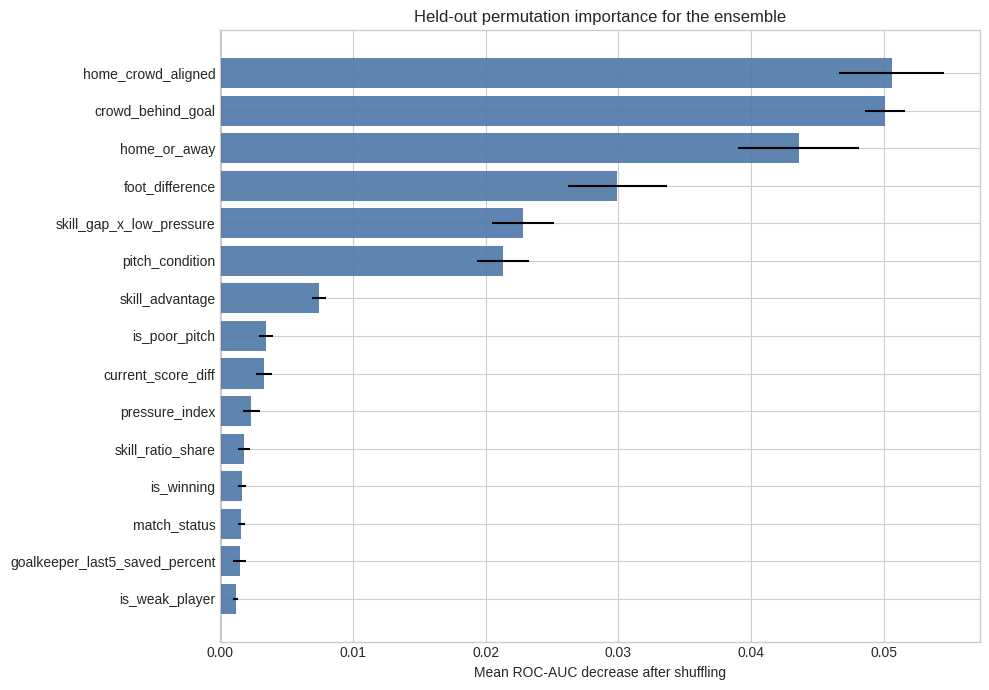

In [10]:
top_permutation = permutation_summary.head(15).sort_values(
    "mean_auc_drop"
)

fig, axis = plt.subplots(figsize=(10, 7))
axis.barh(
    top_permutation["feature"],
    top_permutation["mean_auc_drop"],
    xerr=top_permutation["std_auc_drop"].fillna(0),
    color="#4C78A8",
    alpha=0.9,
)
axis.axvline(0, color="black", linewidth=1)
axis.set(
    title="Held-out permutation importance for the ensemble",
    xlabel="Mean ROC-AUC decrease after shuffling",
    ylabel="",
)
plt.tight_layout()
plt.show()


### Built-in tree importance

This is a second opinion from CatBoost and LightGBM. Values are normalized inside each model and fold, then averaged.

Agreement with permutation importance increases confidence. Disagreement is normal because the methods ask different questions.


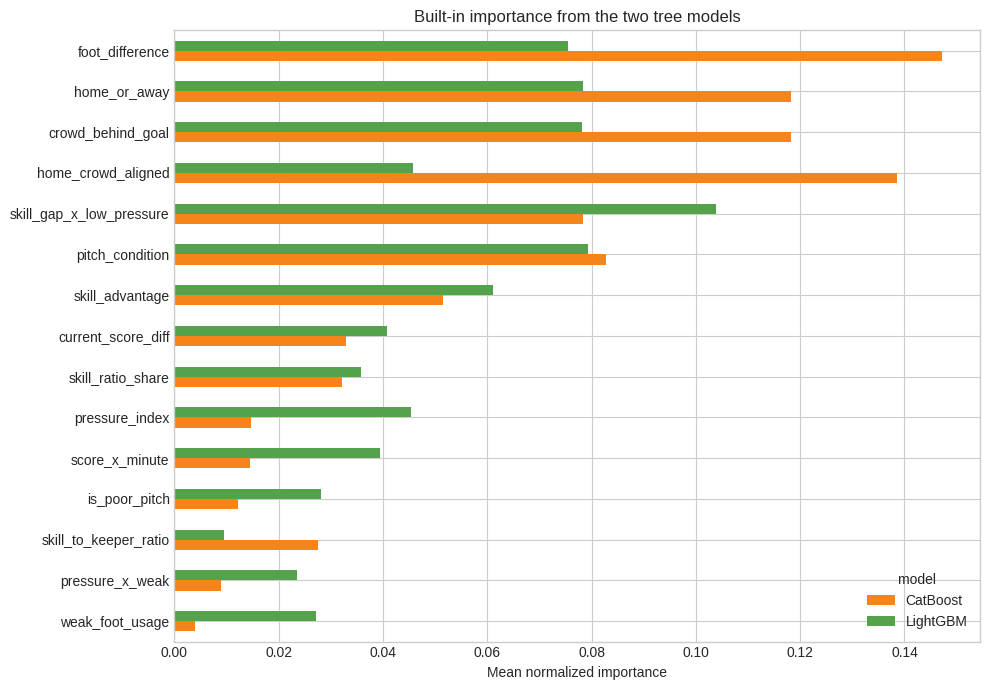

Top-10 overlap: 9/10
Features supported by both methods: ['crowd_behind_goal', 'current_score_diff', 'foot_difference', 'home_crowd_aligned', 'home_or_away', 'pitch_condition', 'pressure_index', 'skill_advantage', 'skill_gap_x_low_pressure']


In [11]:
builtin_by_fold = pd.DataFrame(builtin_rows)
builtin_summary = builtin_by_fold.groupby(
    ["model", "feature"], as_index=False
).agg(mean_importance=("importance", "mean"))

top_builtin_features = (
    builtin_summary.groupby("feature")["mean_importance"]
    .mean()
    .nlargest(15)
    .index
)
builtin_plot = builtin_summary.loc[
    builtin_summary["feature"].isin(top_builtin_features)
].pivot(index="feature", columns="model", values="mean_importance").fillna(0)
builtin_plot = builtin_plot.loc[
    builtin_plot.mean(axis=1).sort_values().index
]

builtin_plot.plot.barh(figsize=(10, 7), color=["#F58518", "#54A24B"])
plt.title("Built-in importance from the two tree models")
plt.xlabel("Mean normalized importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

permutation_top10 = set(permutation_summary.head(10)["feature"])
builtin_top10 = set(
    builtin_summary.groupby("feature")["mean_importance"]
    .mean().nlargest(10).index
)
agreement = sorted(permutation_top10 & builtin_top10)
print(f"Top-10 overlap: {len(agreement)}/10")
print("Features supported by both methods:", agreement)


### Partial dependence: direction of an effect

A **partial-dependence plot (PDP)** varies one feature and averages the model’s predicted probability.

We show the three most important numerical features for LightGBM. This explains one ensemble member, not the whole ensemble. Treat the curve as a model pattern—not proof that changing the feature causes the outcome.


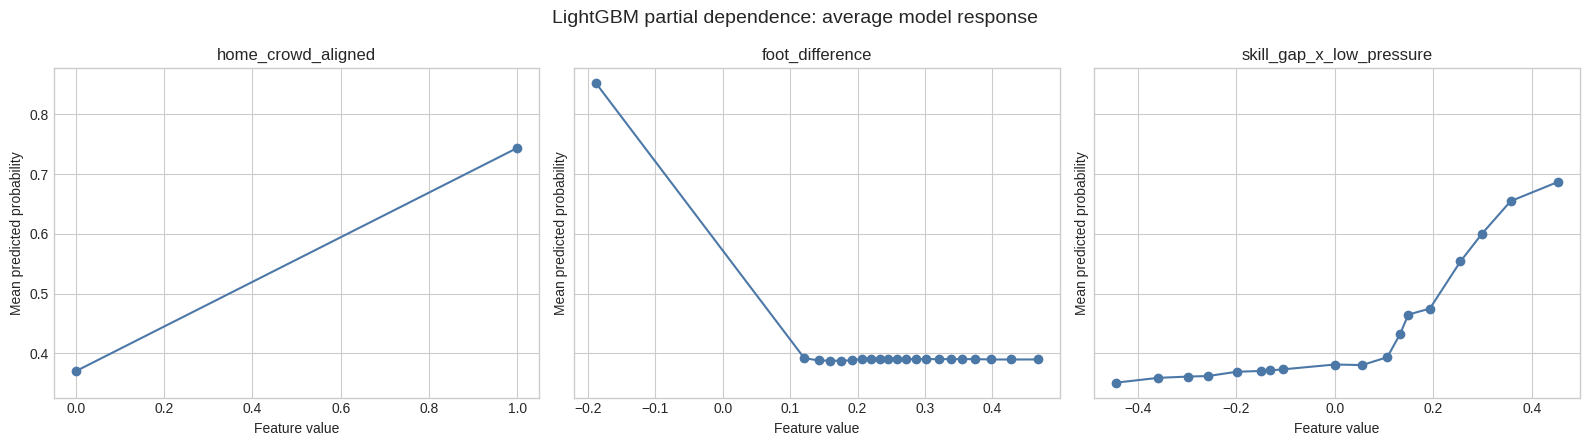

In [12]:
top_pdp_features = [
    feature for feature in permutation_summary["feature"]
    if feature in numerical_columns
][:3]

pdp_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", clone(base_models["LightGBM"])),
])
pdp_pipeline.fit(X, y)

X_pdp = X.sample(n=min(3000, len(X)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(
    1, len(top_pdp_features), figsize=(16, 4.5), sharey=True
)
axes = np.atleast_1d(axes)
pdp_rows = []

for axis, feature in zip(axes, top_pdp_features):
    observed_values = X_pdp[feature].dropna()
    unique_values = np.sort(observed_values.unique())
    if len(unique_values) <= 15:
        grid = unique_values
    else:
        grid = np.unique(np.quantile(
            observed_values, np.linspace(0.05, 0.95, 21)
        ))

    mean_predictions = []
    for value in grid:
        changed = X_pdp.copy()
        changed[feature] = value
        mean_prediction = pdp_pipeline.predict_proba(changed)[:, 1].mean()
        mean_predictions.append(mean_prediction)
        pdp_rows.append({
            "feature": feature,
            "value": value,
            "mean_predicted_probability": mean_prediction,
        })

    axis.plot(grid, mean_predictions, marker="o", color="#4C78A8")
    axis.set(
        title=feature,
        xlabel="Feature value",
        ylabel="Mean predicted probability",
    )

pdp_summary = pd.DataFrame(pdp_rows)
fig.suptitle("LightGBM partial dependence: average model response", fontsize=14)
plt.tight_layout()
plt.show()


## 5. Overall error analysis

- **False positive (FP):** predicted scored, but the penalty was missed.
- **False negative (FN):** predicted missed, but the penalty was scored.
- **Specificity:** fraction of actual misses correctly predicted as misses.
- **High-confidence error:** a wrong prediction made far from the threshold.

The frozen class rule is calibrated probability `>= 0.50`.


In [13]:
oof_prediction = (oof_calibrated_probability >= 0.50).astype(int)
tn, fp, fn, tp = confusion_matrix(y, oof_prediction, labels=[0, 1]).ravel()
specificity = tn / (tn + fp)

metric_summary = pd.DataFrame([
    ["F1", f1_score(y, oof_prediction), "Balance of precision and recall"],
    ["Precision", precision_score(y, oof_prediction), "How often predicted scores are correct"],
    ["Recall", recall_score(y, oof_prediction), "How many actual scores are found"],
    ["Specificity", specificity, "How many actual misses are found"],
    ["Accuracy", accuracy_score(y, oof_prediction), "Fraction of all correct classes"],
    ["Balanced accuracy", balanced_accuracy_score(y, oof_prediction), "Average of recall and specificity"],
    ["ROC-AUC", roc_auc_score(y, oof_calibrated_probability), "Probability ranking quality"],
], columns=["metric", "OOF value", "beginner meaning"])
display(metric_summary.style.hide(axis="index").format({"OOF value": "{:.4f}"}))


metric,OOF value,beginner meaning
F1,0.9491,Balance of precision and recall
Precision,0.9539,How often predicted scores are correct
Recall,0.9445,How many actual scores are found
Specificity,0.9626,How many actual misses are found
Accuracy,0.9545,Fraction of all correct classes
Balanced accuracy,0.9535,Average of recall and specificity
ROC-AUC,0.9930,Probability ranking quality


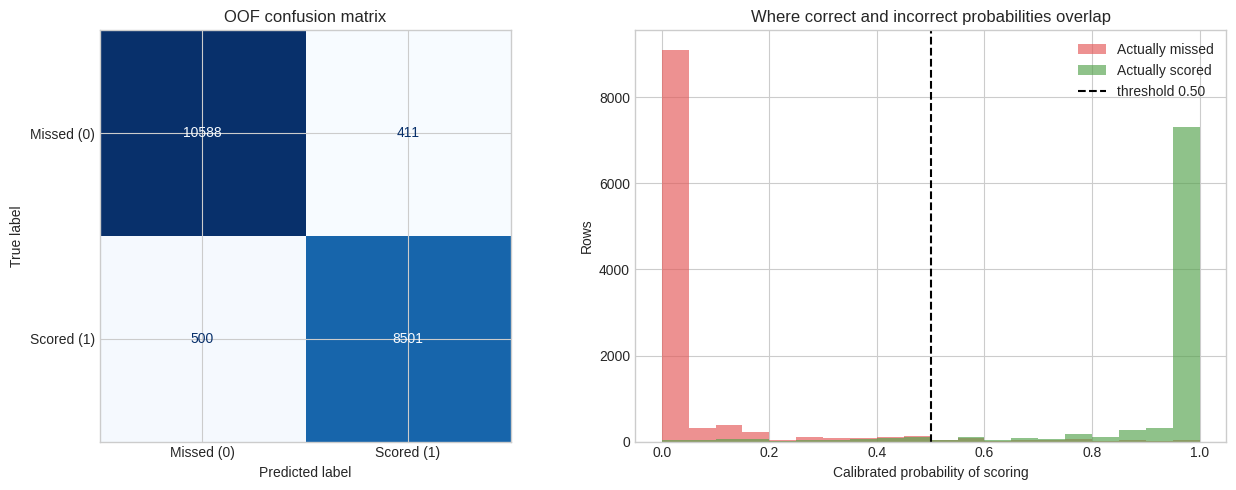

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y,
    oof_prediction,
    labels=[0, 1],
    display_labels=["Missed (0)", "Scored (1)"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("OOF confusion matrix")

axes[1].hist(
    oof_calibrated_probability[y.to_numpy() == 0],
    bins=np.linspace(0, 1, 21),
    alpha=0.65,
    label="Actually missed",
    color="#E45756",
)
axes[1].hist(
    oof_calibrated_probability[y.to_numpy() == 1],
    bins=np.linspace(0, 1, 21),
    alpha=0.65,
    label="Actually scored",
    color="#54A24B",
)
axes[1].axvline(0.50, color="black", linestyle="--", label="threshold 0.50")
axes[1].set(
    title="Where correct and incorrect probabilities overlap",
    xlabel="Calibrated probability of scoring",
    ylabel="Rows",
)
axes[1].legend()

plt.tight_layout()
plt.show()


### Concrete dataset example: the strongest mistakes

Confidence is the probability assigned to the predicted class. A confident error is more informative than a borderline error because the model was strongly wrong.


In [15]:
error_type = np.select(
    [
        (y.to_numpy() == 0) & (oof_prediction == 1),
        (y.to_numpy() == 1) & (oof_prediction == 0),
    ],
    ["False positive", "False negative"],
    default="Correct",
)
prediction_confidence = np.where(
    oof_prediction == 1,
    oof_calibrated_probability,
    1 - oof_calibrated_probability,
)

error_frame = pd.DataFrame({
    "row_index": np.arange(len(train)),
    "id": train["id"].to_numpy(),
    "actual": y.to_numpy(),
    "predicted": oof_prediction,
    "calibrated_probability": oof_calibrated_probability,
    "confidence": prediction_confidence,
    "error_type": error_type,
    "outer_fold": outer_fold_for_row,
})
for feature in [
    "skill_advantage",
    "pressure_index",
    "player_last5_scored_percent",
    "goalkeeper_last5_saved_percent",
    "minute_taken",
    "current_score_diff",
]:
    error_frame[feature] = X[feature].to_numpy()

errors_only = error_frame.loc[
    error_frame["error_type"].ne("Correct")
].sort_values("confidence", ascending=False)
high_confidence_errors = errors_only.loc[errors_only["confidence"] >= 0.90]

print(f"False positives: {(error_type == 'False positive').sum():,}")
print(f"False negatives: {(error_type == 'False negative').sum():,}")
print(f"Errors with at least 0.90 confidence: {len(high_confidence_errors):,}")
display(
    errors_only.head(12).drop(columns="row_index").style.hide(axis="index").format({
        "calibrated_probability": "{:.3f}",
        "confidence": "{:.3f}",
        "skill_advantage": "{:.1f}",
        "pressure_index": "{:.3f}",
    })
)


False positives: 411
False negatives: 500
Errors with at least 0.90 confidence: 128


id,actual,predicted,calibrated_probability,confidence,error_type,outer_fold,skill_advantage,pressure_index,player_last5_scored_percent,goalkeeper_last5_saved_percent,minute_taken,current_score_diff
14251,0,1,1.000,1.000,False positive,4,40.0,0.510,100,60,65.000000,1
8831,0,1,1.000,1.000,False positive,2,-20.0,0.765,80,100,103.000000,0
8252,0,1,0.998,0.998,False positive,5,0.0,0.454,20,20,82.000000,2
16217,1,0,0.002,0.998,False negative,1,-20.0,0.277,20,40,45.000000,2
6377,1,0,0.002,0.998,False negative,1,0.0,0.225,60,60,20.000000,-2
3753,0,1,0.996,0.996,False positive,3,0.0,0.771,0,0,106.000000,0
19765,1,0,0.005,0.995,False negative,1,0.0,0.565,0,0,87.000000,2
8858,1,0,0.005,0.995,False negative,3,0.0,0.258,60,60,16.000000,-1
4576,1,0,0.007,0.993,False negative,5,40.0,0.338,80,40,18.000000,0
11296,0,1,0.992,0.992,False positive,5,80.0,0.573,80,0,149.000000,-3


### Probability-bucket analysis

Fixed probability ranges answer: “When the model predicts around this level, how often is it correct?”

`Observed scoring rate` should be close to `mean predicted`. `Error rate` shows where classification remains difficult.


In [16]:
bucket_frame = pd.DataFrame({
    "probability": oof_calibrated_probability,
    "actual": y.to_numpy(),
    "predicted": oof_prediction,
})
bucket_frame["error"] = bucket_frame["actual"].ne(bucket_frame["predicted"])
bucket_frame["probability range"] = pd.cut(
    bucket_frame["probability"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True,
)
bucket_summary = bucket_frame.groupby(
    "probability range", observed=True
).agg(
    rows=("actual", "size"),
    mean_predicted=("probability", "mean"),
    observed_scoring_rate=("actual", "mean"),
    error_rate=("error", "mean"),
).reset_index()

display(bucket_summary.style.hide(axis="index").format({
    "mean_predicted": "{:.3f}",
    "observed_scoring_rate": "{:.3f}",
    "error_rate": "{:.3f}",
}))


probability range,rows,mean_predicted,observed_scoring_rate,error_rate
"(-0.001, 0.1]",9476,0.005,0.006,0.006
"(0.1, 0.2]",719,0.147,0.150,0.150
"(0.2, 0.3]",218,0.255,0.303,0.303
"(0.3, 0.4]",263,0.356,0.342,0.342
"(0.4, 0.5]",435,0.453,0.451,0.425
"(0.5, 0.6]",264,0.572,0.553,0.447
"(0.6, 0.7]",189,0.659,0.667,0.333
"(0.7, 0.8]",311,0.751,0.720,0.280
"(0.8, 0.9]",434,0.867,0.846,0.154
"(0.9, 1.0]",7691,0.991,0.991,0.009


## 6. Subgroup error analysis

A **subgroup** is a meaningful slice such as one match type or pitch condition.

We compare groups with at least 100 rows. A high error rate is a signal to investigate, not automatic proof of bias or a reason to add a special rule.


In [17]:
subgroup_columns = [
    "jersey_color",
    "match_type",
    "home_or_away",
    "pitch_condition",
    "crowd_behind_goal",
]
subgroup_rows = []

for feature in subgroup_columns:
    values = train[feature].astype("string").fillna("<missing>")
    for value in values.unique():
        mask = values.eq(value).to_numpy()
        group_actual = y.to_numpy()[mask]
        group_prediction = oof_prediction[mask]
        group_probability = oof_calibrated_probability[mask]
        group_tn, group_fp, group_fn, group_tp = confusion_matrix(
            group_actual, group_prediction, labels=[0, 1]
        ).ravel()
        negatives = group_tn + group_fp
        positives = group_tp + group_fn
        subgroup_rows.append({
            "feature": feature,
            "group": str(value),
            "rows": int(mask.sum()),
            "actual_scoring_rate": group_actual.mean(),
            "mean_probability": group_probability.mean(),
            "f1": f1_score(group_actual, group_prediction, zero_division=0),
            "error_rate": np.mean(group_actual != group_prediction),
            "false_positive_rate": group_fp / negatives if negatives else np.nan,
            "false_negative_rate": group_fn / positives if positives else np.nan,
        })

subgroup_summary = pd.DataFrame(subgroup_rows)
stable_subgroups = subgroup_summary.loc[
    subgroup_summary["rows"] >= 100
].copy()
display(
    stable_subgroups.sort_values("error_rate", ascending=False)
    .head(15)
    .style.hide(axis="index")
    .format({
        "actual_scoring_rate": "{:.3f}",
        "mean_probability": "{:.3f}",
        "f1": "{:.3f}",
        "error_rate": "{:.3f}",
        "false_positive_rate": "{:.3f}",
        "false_negative_rate": "{:.3f}",
    })
)


feature,group,rows,actual_scoring_rate,mean_probability,f1,error_rate,false_positive_rate,false_negative_rate
jersey_color,,639,0.446,0.451,0.934,0.059,0.056,0.063
home_or_away,Neutral,4227,0.392,0.393,0.924,0.059,0.045,0.081
jersey_color,White,2515,0.445,0.444,0.938,0.054,0.044,0.068
jersey_color,Red,2449,0.446,0.448,0.943,0.051,0.044,0.059
crowd_behind_goal,Home,10682,0.589,0.590,0.958,0.050,0.057,0.045
pitch_condition,Good,7856,0.465,0.464,0.946,0.050,0.040,0.060
match_type,League,9330,0.442,0.439,0.944,0.049,0.034,0.067
match_type,Friendly,1876,0.479,0.474,0.951,0.047,0.038,0.057
jersey_color,Purple,2401,0.458,0.462,0.949,0.047,0.045,0.048
pitch_condition,Excellent,4574,0.512,0.506,0.954,0.047,0.038,0.055


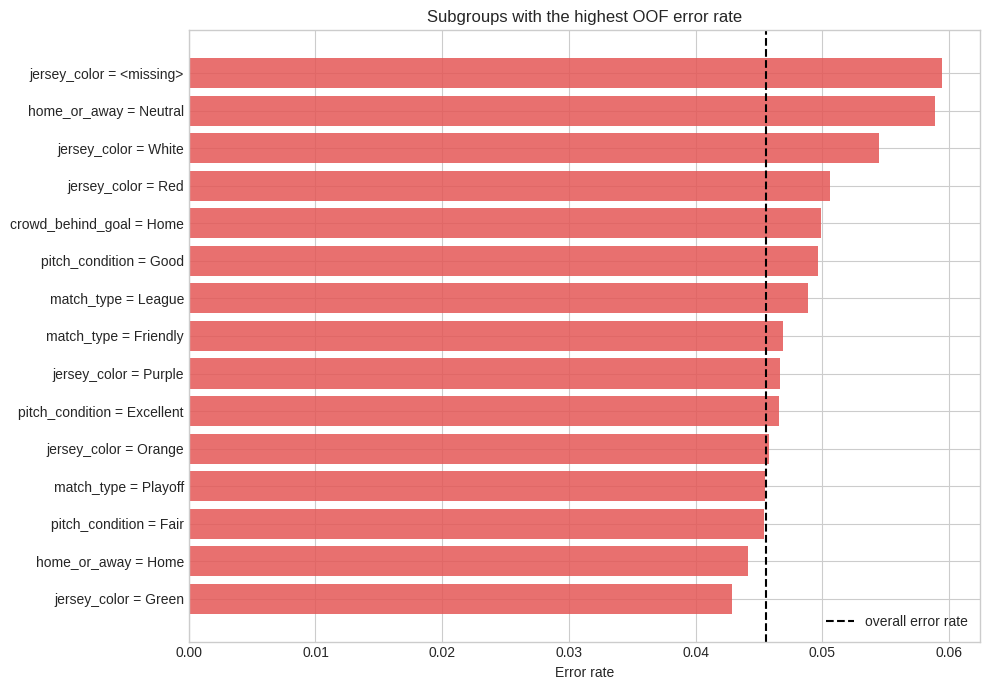

In [18]:
worst_subgroups = stable_subgroups.nlargest(15, "error_rate").copy()
worst_subgroups["label"] = (
    worst_subgroups["feature"] + " = " + worst_subgroups["group"]
)
worst_subgroups = worst_subgroups.sort_values("error_rate")

fig, axis = plt.subplots(figsize=(10, 7))
axis.barh(
    worst_subgroups["label"],
    worst_subgroups["error_rate"],
    color="#E45756",
    alpha=0.85,
)
axis.axvline(
    np.mean(y.to_numpy() != oof_prediction),
    color="black",
    linestyle="--",
    label="overall error rate",
)
axis.set(
    title="Subgroups with the highest OOF error rate",
    xlabel="Error rate",
    ylabel="",
)
axis.legend()
plt.tight_layout()
plt.show()


## 7. Concrete local examples

For the most confident false positive and false negative, we replace one feature at a time with its outer-training median or most-common category.

`Probability change` is the change in the **raw ensemble** probability after replacement. This avoids flat steps from isotonic calibration.

This is a local sensitivity check. It does **not** prove causality, and replacing one engineered feature can create an unusual combination with related features.


In [19]:
local_rows = []
selected_error_rows = []

for requested_error in ["False positive", "False negative"]:
    candidates = errors_only.loc[
        errors_only["error_type"].eq(requested_error)
    ]
    if candidates.empty:
        continue
    selected = candidates.iloc[0]
    selected_error_rows.append(selected)
    row_index = int(selected["row_index"])
    fold_id = int(selected["outer_fold"])
    bundle = fold_bundles[fold_id]
    original_row = X.iloc[[row_index]].copy()
    baseline_raw_probability = float(
        predict_ensemble(bundle["models"], original_row)[0]
    )

    row_sensitivity = []
    for feature in X.columns:
        changed_row = original_row.copy()
        reference_value = bundle["references"][feature]
        changed_row.loc[changed_row.index[0], feature] = reference_value
        changed_probability = float(
            predict_ensemble(bundle["models"], changed_row)[0]
        )
        row_sensitivity.append({
            "error_type": requested_error,
            "id": selected["id"],
            "feature": feature,
            "original_value": str(original_row.iloc[0][feature]),
            "reference_value": str(reference_value),
            "baseline_raw_probability": baseline_raw_probability,
            "probability_after_replacement": changed_probability,
            "probability_change": changed_probability - baseline_raw_probability,
        })

    row_sensitivity = sorted(
        row_sensitivity,
        key=lambda row: abs(row["probability_change"]),
        reverse=True,
    )[:8]
    local_rows.extend(row_sensitivity)

local_sensitivity = pd.DataFrame(local_rows)
display(local_sensitivity.style.hide(axis="index").format({
    "baseline_raw_probability": "{:.3f}",
    "probability_after_replacement": "{:.3f}",
    "probability_change": "{:+.3f}",
}))


error_type,id,feature,original_value,reference_value,baseline_raw_probability,probability_after_replacement,probability_change
False positive,14251,foot_difference,-0.5049999999999999,0.262,0.988,0.560,-0.428
False positive,14251,crowd_behind_goal,Away,Home,0.988,0.967,-0.021
False positive,14251,weak_foot_usage,0.833,0.344,0.988,0.971,-0.017
False positive,14251,strong_foot_usage,0.328,0.615,0.988,0.986,-0.002
False positive,14251,pressure_index,0.5104166666666666,0.35833333333333334,0.988,0.986,-0.002
False positive,14251,skill_to_keeper_ratio,1.639344262295082,0.975609756097561,0.988,0.987,-0.001
False positive,14251,match_type,Playoff,League,0.988,0.987,-0.001
False positive,14251,pressure_skill,100.0,0.0,0.988,0.989,+0.001
False negative,16217,skill_ratio_share,0.2857142857142857,0.4615384615384615,0.052,0.140,+0.088
False negative,16217,skill_advantage,-20,0.0,0.052,0.102,+0.050


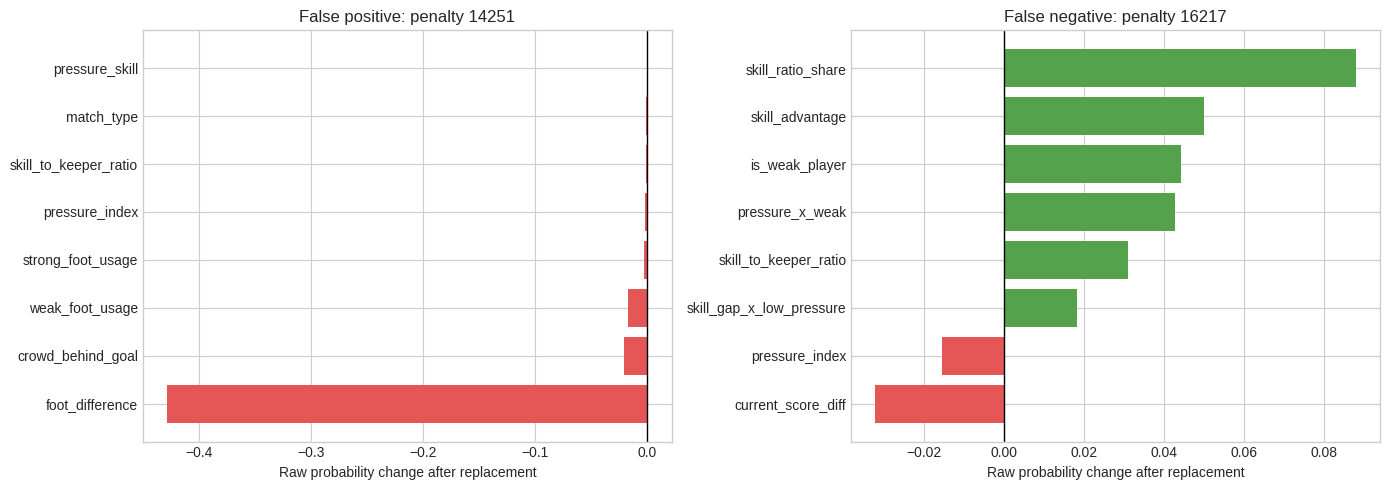

In [20]:
error_labels = local_sensitivity["error_type"].unique()
fig, axes = plt.subplots(1, len(error_labels), figsize=(14, 5))
axes = np.atleast_1d(axes)

for axis, error_label in zip(axes, error_labels):
    subset = local_sensitivity.loc[
        local_sensitivity["error_type"].eq(error_label)
    ].sort_values("probability_change")
    colors = np.where(subset["probability_change"] >= 0, "#54A24B", "#E45756")
    axis.barh(subset["feature"], subset["probability_change"], color=colors)
    axis.axvline(0, color="black", linewidth=1)
    axis.set(
        title=f"{error_label}: penalty {subset['id'].iloc[0]}",
        xlabel="Raw probability change after replacement",
        ylabel="",
    )

plt.tight_layout()
plt.show()


## 8. What to do with these findings

- Keep features that are supported across held-out permutation and tree importance.
- Treat low importance as a removal **candidate**, not an automatic deletion.
- Review confident FP and FN rows for missing interactions or data-quality issues.
- Monitor subgroups with high error rates, especially when they also have enough rows.
- Do not create special rules from the same OOF errors without a new validation test.

The next notebook will fit the frozen pipeline on all training rows and create the final test predictions. Only after those predictions are frozen may an organizer-only audit compare them with hidden labels.


In [21]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

top_features = permutation_summary.head(10)["feature"].tolist()
overall_error_rate = float(np.mean(y.to_numpy() != oof_prediction))

print(f"Frozen calibrated-ensemble OOF F1: {f1_score(y, oof_prediction):.4f}")
print(f"Overall OOF error rate: {overall_error_rate:.4f}")
print("Top five held-out permutation features:")
for rank, feature in enumerate(top_features[:5], start=1):
    value = permutation_summary.loc[
        permutation_summary["feature"].eq(feature), "mean_auc_drop"
    ].iloc[0]
    print(f"  {rank}. {feature}: AUC drop {value:+.4f}")

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)

permutation_summary.to_csv(results_dir / "14_permutation_importance.csv", index=False)
builtin_summary.to_csv(results_dir / "14_tree_importance.csv", index=False)
pdp_summary.to_csv(results_dir / "14_partial_dependence.csv", index=False)
error_frame.to_csv(results_dir / "14_oof_error_rows.csv", index=False)
bucket_summary.to_csv(results_dir / "14_probability_buckets.csv", index=False)
subgroup_summary.to_csv(results_dir / "14_subgroup_errors.csv", index=False)
local_sensitivity.to_csv(results_dir / "14_local_sensitivity.csv", index=False)

summary = {
    "dataset_fingerprint": dataset_fingerprint,
    "oof_f1": float(f1_score(y, oof_prediction)),
    "oof_roc_auc": float(roc_auc_score(y, oof_calibrated_probability)),
    "overall_error_rate": overall_error_rate,
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "high_confidence_errors": int(len(high_confidence_errors)),
    "top_permutation_features": top_features,
}
with (results_dir / "14_interpretation_error_summary.json").open(
    "w", encoding="utf-8"
) as handle:
    json.dump(summary, handle, indent=2)

print(f"Saved interpretation and error-analysis artifacts to: {results_dir}")


Frozen calibrated-ensemble OOF F1: 0.9491
Overall OOF error rate: 0.0456
Top five held-out permutation features:
  1. home_crowd_aligned: AUC drop +0.0506
  2. crowd_behind_goal: AUC drop +0.0501
  3. home_or_away: AUC drop +0.0436
  4. foot_difference: AUC drop +0.0299
  5. skill_gap_x_low_pressure: AUC drop +0.0228
Saved interpretation and error-analysis artifacts to: /kaggle/working


## Why this decision is justified

**Technical evidence:** importance is measured on untouched folds, errors come from OOF predictions, and calibration is fitted inside each outer training fold.

**Theoretical reason:** global importance describes overall model dependence, while error, subgroup, and local analyses reveal cases that one average score can hide. None of these explanations is automatically causal.
